# Life Expectancy at Birth, 2000-2024: an exploratory analysis

**Assigned dataset (primary indicator):** life expectancy at birth, total (years).
**Supporting indicators:** GDP per capita (current US$) and the unemployment rate (% of labour force, national estimate).

This notebook follows the structure of `notebooks/gdp_per_capita.ipynb`, but looks at the same World Bank data from a different angle: life expectancy is the thing we want to understand, and GDP and unemployment are used as context. Everything is reported as an *association*; none of it is a causal claim.

**Contents**
1. Cursory examination of the CSV files
2. Loading and merging into data frames
3. EDA: (a) understanding the data, (b) statistics and distributions, (c) visualisations, (d) missing values and outliers, (e) trends, patterns and relationships
4. The eight questions

## 1. Cursory examination of the CSV files

Three files sit in `data/`. Before loading anything with pandas, look at them as plain text: how many lines, what the header looks like, what a data row looks like and what sits at the end of the file.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

%matplotlib inline
sns.set_theme(style='whitegrid')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 40)

files = {'combined': 'data/All_three_combined.csv',
         'gdp_lei': 'data/GDP & LEI.csv',
         'gdp_uem': 'data/GDP & UEM.csv'}

for name, path in files.items():
    with open(path, encoding='utf-8-sig') as f:
        lines = f.read().splitlines()
    print(f'{name}: {len(lines)} lines in {path}')
    print('  header :', lines[0][:110], '...')
    print('  row 1  :', lines[1][:110], '...')
    print('  row 3  :', lines[3][:110], '...')
    print('  last 5 lines:')
    for l in lines[-5:]:
        print('     ', l[:110])
    print()

combined: 799 lines in data/All_three_combined.csv
  header : Country Name,Country Code,Series Name,Series Code,2000 [YR2000],2001 [YR2001],2002 [YR2002],2003 [YR2003],2004 ...
  row 1  : Afghanistan,AFG,GDP per capita (current US$),NY.GDP.PCAP.CD,174.930991430166,138.706821676113,178.954088379235 ...
  row 3  : Afghanistan,AFG,"Unemployment, total (% of total labor force) (national estimate)",SL.UEM.TOTL.NE.ZS,..,..,.., ...
  last 5 lines:
      Upper middle income,UMC,"Life expectancy at birth, total (years)",SP.DYN.LE00.IN,70.7453581446278,71.057454006
      Upper middle income,UMC,"Unemployment, total (% of total labor force) (national estimate)",SL.UEM.TOTL.NE.ZS,5
      World,WLD,GDP per capita (current US$),NY.GDP.PCAP.CD,5512.56177163867,5404.20269822848,5539.32465002692,6129.
      World,WLD,"Life expectancy at birth, total (years)",SP.DYN.LE00.IN,67.650477873849,67.9451852910729,68.2313680
      World,WLD,"Unemployment, total (% of total labor force) (national estimate)",SL.U

**What the cursory look tells us**

- Every file is in the World Bank "wide" layout: one row per **country x indicator**, one column per year (`2000 [YR2000]` ... `2024 [YR2024]`), so the year is hidden in the column names and has to be reshaped.
- Missing values are written as `..` (two dots), not as an empty cell, so a plain `read_csv` will read the year columns as text.
- The last lines of `GDP & LEI.csv` and `GDP & UEM.csv` are not data: they are footer notes (data source, "Last Updated"). They have no series code and must be dropped.
- Four descriptive columns (`Country Name`, `Country Code`, `Series Name`, `Series Code`) identify each row. The series names are long, so the short series codes are a better key.
- Besides countries, the files contain regional and income-group aggregates (for example `WLD` = World, `EMU` = Euro area). Left in, they would double count countries, so they are removed before analysis.
- `All_three_combined.csv` appears to hold all three indicators, while the other two files each hold GDP plus one indicator. We check below that they agree before choosing which to use.

## 2. Loading the data and merging

Plan:
1. Read each file with `na_values='..'` so the year columns are numeric, and drop the footer rows.
2. Check that the three files agree with each other (GDP appears in all three).
3. Melt to a long table (one row per country-year-indicator), then pivot to one row per **country-year** with one column per indicator. This single merged panel is the main data frame for the analysis.
4. Remove regional and income-group aggregates, and add a continent for each country.

In [2]:
def read_wb(path):
    d = pd.read_csv(path, na_values='..', encoding='utf-8-sig')
    return d.dropna(subset=['Series Code']).reset_index(drop=True)   # footer lines have no series code

raw = {name: read_wb(path) for name, path in files.items()}
for name, d in raw.items():
    print(f'{name:9s} shape {d.shape}, series: {sorted(d["Series Code"].unique())}')

year_cols = [c for c in raw['combined'].columns if '[YR' in c]
print('\nyear columns:', year_cols[0], '...', year_cols[-1], f'({len(year_cols)} years)')

# Do the three files agree? Compare every indicator they share, value by value.
key = ['Country Code', 'Series Code']
base = raw['combined'].set_index(key)[year_cols]
for name in ['gdp_lei', 'gdp_uem']:
    other = raw[name].set_index(key)[year_cols]
    shared = other.index.intersection(base.index)
    same = np.allclose(base.loc[shared].to_numpy(float), other.loc[shared].to_numpy(float), equal_nan=True)
    print(f'{name}: {len(shared)} shared rows, identical to combined file: {same}')

combined  shape (798, 29), series: ['NY.GDP.PCAP.CD', 'SL.UEM.TOTL.NE.ZS', 'SP.DYN.LE00.IN']
gdp_lei   shape (532, 29), series: ['NY.GDP.PCAP.CD', 'SP.DYN.LE00.IN']
gdp_uem   shape (532, 29), series: ['NY.GDP.PCAP.CD', 'SL.UEM.TOTL.NE.ZS']

year columns: 2000 [YR2000] ... 2024 [YR2024] (25 years)
gdp_lei: 532 shared rows, identical to combined file: True
gdp_uem: 532 shared rows, identical to combined file: True


The three files hold identical numbers for every shared row, so `All_three_combined.csv` is used as the single source. The two smaller files add nothing new.

Now reshape to one row per country-year.

In [3]:
short = {'NY.GDP.PCAP.CD': 'gdp_per_capita',
         'SP.DYN.LE00.IN': 'life_expectancy',
         'SL.UEM.TOTL.NE.ZS': 'unemployment_rate'}

long = raw['combined'].melt(id_vars=['Country Name', 'Country Code', 'Series Code'],
                            value_vars=year_cols, var_name='year', value_name='value')
long['year'] = long['year'].str[:4].astype(int)
long['indicator'] = long['Series Code'].map(short)

panel_all = (long.set_index(['Country Name', 'Country Code', 'year', 'indicator'])['value']
                 .unstack('indicator').reset_index())
panel_all.columns.name = None

aggregate_codes = {
    'AFE', 'AFW', 'ARB', 'CEB', 'CSS', 'EAP', 'EAR', 'EAS', 'ECA', 'ECS', 'EMU', 'EUU',
    'FCS', 'FCV', 'HIC', 'HPC', 'IBD', 'IBT', 'IDA', 'IDB', 'IDX', 'INX', 'LAC', 'LCN', 'LDC',
    'LIC', 'LMC', 'LMY', 'LTE', 'MEA', 'MIC', 'MNA', 'NAC', 'OED', 'OSS', 'PRE', 'PSS',
    'PST', 'SAS', 'SSA', 'SSF', 'SST', 'TEA', 'TEC', 'TLA', 'TMN', 'TSA', 'TSS', 'UMC', 'WLD'}
aggregates = panel_all[panel_all['Country Code'].isin(aggregate_codes)]
df = panel_all[~panel_all['Country Code'].isin(aggregate_codes)].copy()

continent_codes = {
    'Africa': 'DZA AGO BEN BWA BFA BDI CPV CMR CAF TCD COM COD COG CIV DJI EGY GNQ ERI SWZ ETH GAB GMB GHA GIN GNB '
              'KEN LSO LBR LBY MDG MWI MLI MRT MUS MAR MOZ NAM NER NGA RWA STP SEN SYC SLE SOM ZAF SSD SDN TZA TGO '
              'TUN UGA ZMB ZWE',
    'Asia': 'AFG ARM AZE BHR BGD BTN BRN KHM CHN GEO HKG IND IDN IRN IRQ ISR JPN JOR KAZ KWT KGZ LAO LBN MAC MYS '
            'MDV MNG MMR NPL PRK OMN PAK PSE PHL QAT SAU SGP KOR LKA SYR TJK THA TLS TUR TKM ARE UZB VNM YEM',
    'Europe': 'ALB AND AUT BLR BEL BIH BGR HRV CYP CZE DNK EST FRO FIN FRA DEU GIB GRC HUN ISL IRL IMN ITA XKX LVA '
              'LIE LTU LUX MLT MDA MCO MNE NLD MKD NOR POL PRT ROU RUS SMR SRB SVK SVN ESP SWE CHE UKR GBR CHI',
    'North America': 'ATG BHS BRB BLZ BMU CAN CYM CRI CUB CUW DMA DOM SLV GRL GRD GTM HTI HND JAM MEX NIC PAN PRI '
                     'KNA LCA MAF VCT SXM TTO TCA USA VGB VIR ABW',
    'South America': 'ARG BOL BRA CHL COL ECU GUY PRY PER SUR URY VEN',
    'Oceania': 'ASM AUS FJI PYF GUM KIR MHL FSM NRU NCL NZL MNP PLW PNG WSM SLB TON TUV VUT'}
continent_of = {code: cont for cont, codes in continent_codes.items() for code in codes.split()}
df['continent'] = df['Country Code'].map(continent_of)
df['log_gdp'] = np.log10(df['gdp_per_capita'])
cont_order = ['Africa', 'Asia', 'Europe', 'North America', 'South America', 'Oceania']

print(f'Entities in file: {panel_all["Country Code"].nunique()}; aggregates removed: {aggregates["Country Code"].nunique()}; '
      f'countries kept: {df["Country Code"].nunique()}')
print('Countries with no continent assigned:', sorted(df.loc[df['continent'].isna(), 'Country Name'].unique()) or 'none')
print('\nCountries per continent:')
print(df.groupby('continent')['Country Code'].nunique().reindex(cont_order).to_string())
df.head()

Entities in file: 266; aggregates removed: 49; countries kept: 217
Countries with no continent assigned: none

Countries per continent:
continent
Africa           54
Asia             49
Europe           49
North America    34
South America    12
Oceania          19


,Country Name,Country Code,year,gdp_per_capita,life_expectancy,unemployment_rate,continent,log_gdp
0,Afghanistan,AFG,2000,174.930991,55.005,NaN,Asia,2.242867
1,Afghanistan,AFG,2001,138.706822,55.511,NaN,Asia,2.142098
2,Afghanistan,AFG,2002,178.954088,56.225,NaN,Asia,2.252742
3,Afghanistan,AFG,2003,198.871116,57.171,NaN,Asia,2.298572
4,Afghanistan,AFG,2004,221.763654,57.810,NaN,Asia,2.345890


## 3. Exploratory data analysis

### 5a. Understanding the data: attributes, types, size and significant fields

In [4]:
print(f'Merged country-year panel: {df.shape[0]:,} rows x {df.shape[1]} columns '
      f'({df["Country Code"].nunique()} countries x {df["year"].nunique()} years = {df["Country Code"].nunique() * df["year"].nunique():,} possible rows)')
print(f'Years: {df["year"].min()} to {df["year"].max()}; memory: {df.memory_usage(deep=True).sum() / 1024:.0f} KB\n')
df.info()

Merged country-year panel: 5,425 rows x 8 columns (217 countries x 25 years = 5,425 possible rows)
Years: 2000 to 2024; memory: 1138 KB

<class 'pandas.core.frame.DataFrame'>
Index: 5425 entries, 0 to 6649
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Country Name       5425 non-null   object 
 1   Country Code       5425 non-null   object 
 2   year               5425 non-null   int64  
 3   gdp_per_capita     5242 non-null   float64
 4   life_expectancy    5425 non-null   float64
 5   unemployment_rate  3177 non-null   float64
 6   continent          5425 non-null   object 
 7   log_gdp            5242 non-null   float64
dtypes: float64(4), int64(1), object(3)
memory usage: 381.4+ KB


In [5]:
dictionary = pd.DataFrame([
    ('Country Name', 'text', 'identifier', 'Country or territory name'),
    ('Country Code', 'text', 'identifier', 'World Bank 3-letter code; the key used to remove aggregates and assign continents'),
    ('year', 'integer', 'time', 'Calendar year, 2000-2024 (taken from the "YYYY [YRYYYY]" column names)'),
    ('life_expectancy', 'float', 'PRIMARY indicator', 'Life expectancy at birth, total (years)'),
    ('gdp_per_capita', 'float', 'supporting', 'GDP per capita, current US$ (not adjusted for inflation or local prices)'),
    ('unemployment_rate', 'float', 'supporting', 'Unemployment, % of labour force (national estimate; definitions differ by country)'),
    ('continent', 'text', 'derived', 'Added by us from the country code (the files have no region column)'),
    ('log_gdp', 'float', 'derived', 'log10 of GDP per capita; used because GDP is extremely skewed')],
    columns=['field', 'type', 'role', 'meaning'])
dictionary

,field,type,role,meaning
0,Country Name,text,identifier,Country or territory name
1,Country Code,text,identifier,World Bank 3-letter code; the key used to remo...
2,year,integer,time,"Calendar year, 2000-2024 (taken from the ""YYYY..."
3,life_expectancy,float,PRIMARY indicator,"Life expectancy at birth, total (years)"
4,gdp_per_capita,float,supporting,"GDP per capita, current US$ (not adjusted for ..."
5,unemployment_rate,float,supporting,"Unemployment, % of labour force (national esti..."
6,continent,text,derived,Added by us from the country code (the files h...
7,log_gdp,float,derived,log10 of GDP per capita; used because GDP is e...


In [6]:
print('Rows per indicator in the raw file (country/aggregate x indicator):')
print(raw['combined'].groupby('Series Name').size().to_string())
print(f'\nExample: first and last observed life expectancy per year for 3 countries')
df[df['Country Name'].isin(['Rwanda', 'Japan', 'United States'])].pivot(index='year', columns='Country Name', values='life_expectancy').iloc[[0, 5, 10, 15, 20, 24]].round(1)

Rows per indicator in the raw file (country/aggregate x indicator):
Series Name
GDP per capita (current US$)                                        266
Life expectancy at birth, total (years)                             266
Unemployment, total (% of total labor force) (national estimate)    266

Example: first and last observed life expectancy per year for 3 countries


Country Name,Japan,Rwanda,United States
year,,,
2000,81.1,47.8,76.6
2005,82.0,57.0,77.5
2010,82.8,62.8,78.5
2015,83.8,65.4,78.7
2020,84.6,67.0,77.0
2024,84.0,68.0,78.9


**What 5a shows**

- The merged panel has **5,425 rows = 217 countries x 25 years**, with no duplicate or absent country-year rows. Three numeric indicators sit on top of three identifier/derived columns.
- **Life expectancy is the most complete field: 5,425 of 5,425 values (100%).** That makes it a good primary indicator. GDP per capita is 97% complete and unemployment only 59% complete (3,177 values), so anything involving unemployment rests on a smaller, uneven sample.
- Significant fields: `life_expectancy` (the outcome we study), `year` (trends over time), `Country Code` (key and grouping), `gdp_per_capita` / `log_gdp` and `unemployment_rate` (context), and the derived `continent`.
- `Country Name` and `Country Code` are text; `year` is an integer; the three indicators are floats. The raw year columns had to be reshaped and the `..` placeholders converted to missing values before any of this was possible.

### 5b. Basic statistics and distributions

In [7]:
num_cols = ['life_expectancy', 'gdp_per_capita', 'unemployment_rate']
desc = df[num_cols].describe(percentiles=[.05, .25, .5, .75, .95]).T
desc['skew'] = df[num_cols].skew()
desc['kurtosis'] = df[num_cols].kurt()
desc.round(2)

,count,mean,std,min,5%,25%,50%,75%,95%,max,skew,kurtosis
life_expectancy,5425.0,71.02,8.75,14.66,54.02,65.55,72.66,77.57,82.45,86.50,-0.83,0.63
gdp_per_capita,5242.0,16314.53,25475.38,109.59,450.39,1576.38,5464.72,21289.68,61434.15,288001.57,3.32,16.47
unemployment_rate,3177.0,8.05,6.35,0.00,1.56,3.94,6.37,10.15,20.23,57.00,2.16,7.08


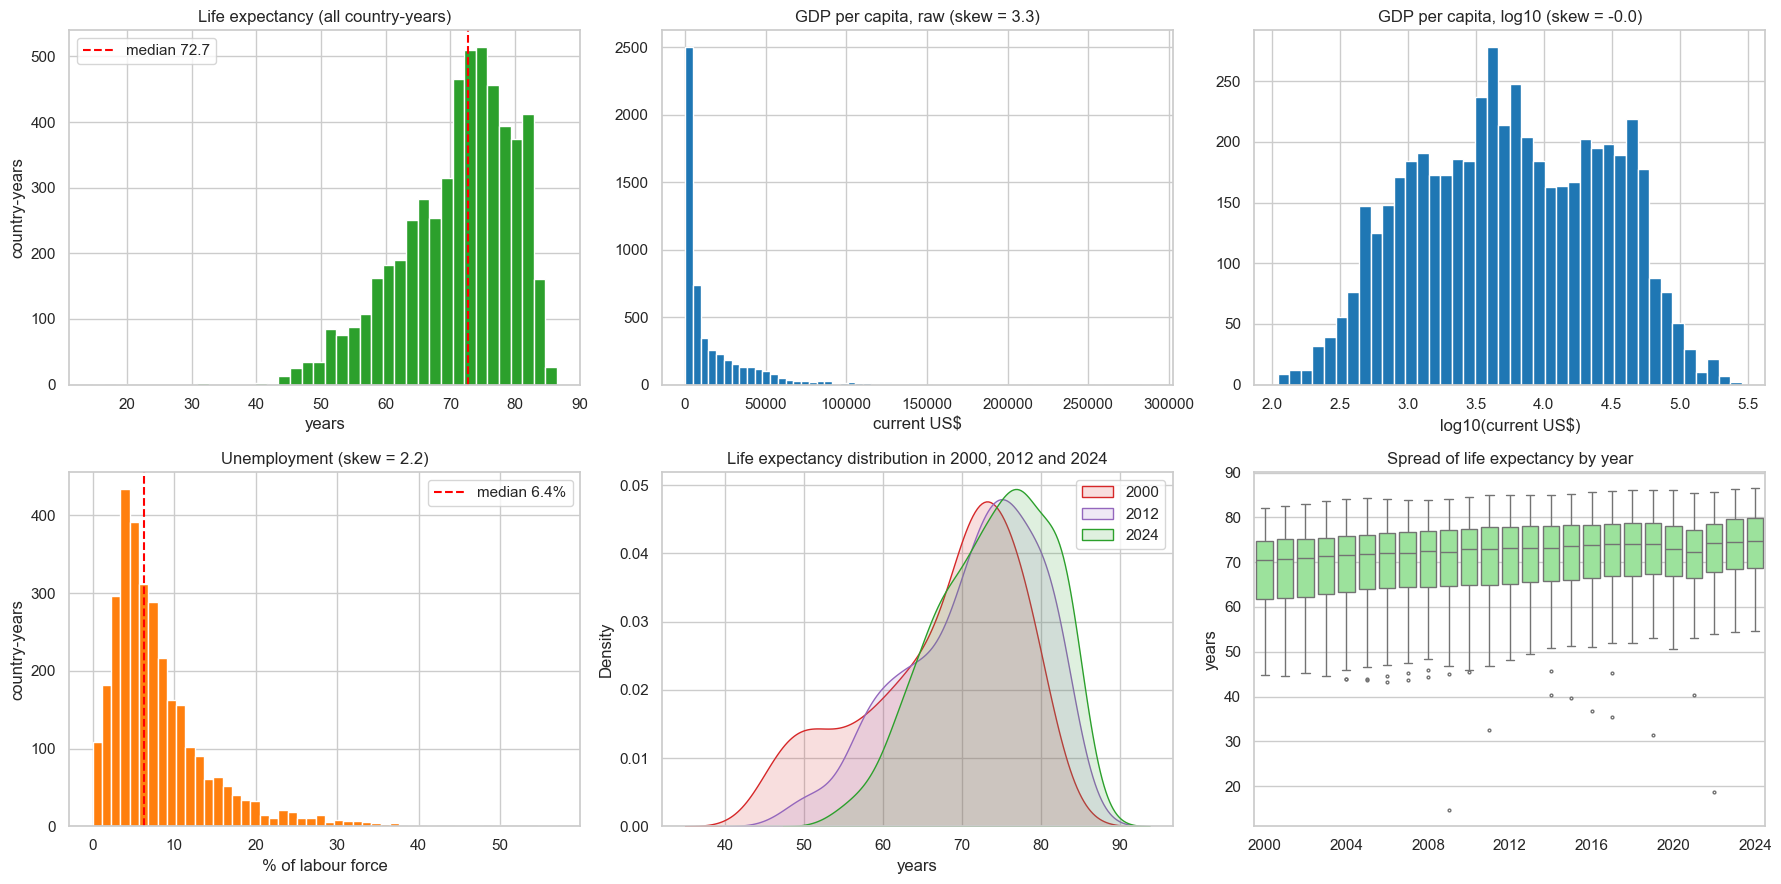

In [8]:
# Figure 1: distributions of the three indicators (every country-year).
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
d = df['life_expectancy'].dropna()
axes[0, 0].hist(d, bins=40, color='tab:green', edgecolor='white')
axes[0, 0].axvline(d.median(), color='red', ls='--', label=f'median {d.median():.1f}')
axes[0, 0].set(title='Life expectancy (all country-years)', xlabel='years', ylabel='country-years')
axes[0, 0].legend()

g = df['gdp_per_capita'].dropna()
axes[0, 1].hist(g, bins=60, color='tab:blue', edgecolor='white')
axes[0, 1].set(title=f'GDP per capita, raw (skew = {g.skew():.1f})', xlabel='current US$')
axes[0, 2].hist(np.log10(g), bins=40, color='tab:blue', edgecolor='white')
axes[0, 2].set(title=f'GDP per capita, log10 (skew = {np.log10(g).skew():.1f})', xlabel='log10(current US$)')

u = df['unemployment_rate'].dropna()
axes[1, 0].hist(u, bins=50, color='tab:orange', edgecolor='white')
axes[1, 0].axvline(u.median(), color='red', ls='--', label=f'median {u.median():.1f}%')
axes[1, 0].set(title=f'Unemployment (skew = {u.skew():.1f})', xlabel='% of labour force', ylabel='country-years')
axes[1, 0].legend()

for yr, c in [(2000, 'tab:red'), (2012, 'tab:purple'), (2024, 'tab:green')]:
    sns.kdeplot(df.loc[df['year'] == yr, 'life_expectancy'].dropna(), ax=axes[1, 1], color=c, label=str(yr), fill=True, alpha=0.15)
axes[1, 1].set(title='Life expectancy distribution in 2000, 2012 and 2024', xlabel='years')
axes[1, 1].legend()

sns.boxplot(data=df, x='year', y='life_expectancy', ax=axes[1, 2], color='lightgreen', fliersize=2)
axes[1, 2].set(title='Spread of life expectancy by year', xlabel='', ylabel='years')
axes[1, 2].set_xticks(range(0, 25, 4)); axes[1, 2].set_xticklabels(range(2000, 2025, 4))
plt.tight_layout()
plt.show()

In [9]:
# Where do the extremes sit, and how unequal is life expectancy between countries each year?
spread = df.groupby('year')['life_expectancy'].agg(['min', 'median', 'max', 'std'])
spread['gap_max_min'] = spread['max'] - spread['min']
print(spread.loc[[2000, 2005, 2010, 2015, 2019, 2020, 2021, 2024]].round(1).to_string())
low, high = df.loc[df['life_expectancy'].idxmin()], df.loc[df['life_expectancy'].idxmax()]
print(f"\nLowest value : {low['life_expectancy']:.1f} years, {low['Country Name']} {low['year']}")
print(f"Highest value: {high['life_expectancy']:.1f} years, {high['Country Name']} {high['year']}")

       min  median   max  std  gap_max_min
year                                      
2000  44.8    70.5  82.1  9.6         37.3
2005  43.6    71.9  84.3  9.3         40.7
2010  45.6    72.9  84.6  8.8         39.1
2015  39.8    73.6  85.3  8.2         45.6
2019  31.5    74.2  86.2  8.0         54.6
2020  50.6    73.0  86.1  7.4         35.5
2021  40.3    72.3  85.5  7.7         45.3
2024  54.6    74.7  86.5  7.1         31.9

Lowest value : 14.7 years, Central African Republic 2009
Highest value: 86.5 years, Monaco 2024


**What 5b shows**

- **Life expectancy** has a mean of 71.0 and a median of 72.7 years, with a standard deviation of 8.8. It is **left-skewed** (skew -0.83): most country-years are clustered at 65-80 years, with a long tail of low values from countries with severe health crises. The middle 50% of country-years lie between 65.6 and 77.6 years.
- **GDP per capita** is the opposite: heavily **right-skewed** (skew 3.3). The mean ($16,315) is three times the median ($5,465), and a handful of tiny rich economies (Monaco, Liechtenstein, Bermuda) reach $140,000-$290,000. On a log10 scale the distribution is close to symmetric, so **all GDP comparisons below use the log scale**.
- **Unemployment** is also right-skewed (skew 2.2): the median is 6.4%, the mean 8.1%, and the maximum 57% (Kosovo). It is on a natural scale, so it is used as it comes.
- **Over time the whole life-expectancy distribution moved right and tightened.** The year-by-year spread (standard deviation) fell from 9.6 years in 2000 to 7.1 in 2024, and the median rose from 70.5 to 74.7. The 2020 and 2021 medians (73.0 and 72.3) fall below the 2019 median (74.2), which is the pandemic showing up in the data.
- The gap between the lowest and highest country is not steady (37 years in 2000, up to 55 in 2019, down to 32 in 2024). The 2019 maximum gap is driven by a single suspicious value for the Central African Republic, discussed in 5d.

### 5d. Missing values and outliers

                   missing  share_%  present
life_expectancy          0      0.0     5425
gdp_per_capita         183      3.4     5242
unemployment_rate     2248     41.4     3177


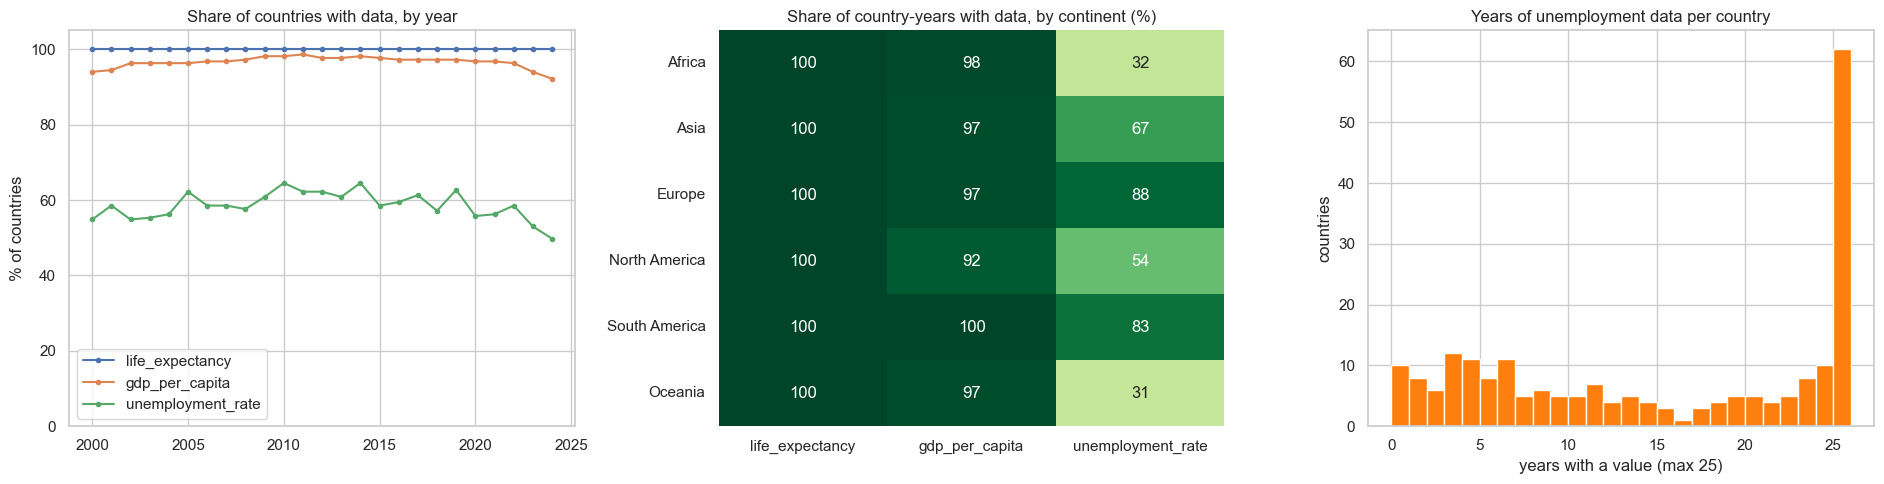

In [10]:
missing = pd.DataFrame({'missing': df[num_cols].isna().sum(), 'share_%': (df[num_cols].isna().mean() * 100).round(1)})
missing['present'] = len(df) - missing['missing']
print(missing.to_string())

# Figure 2: where are the gaps? (share of countries with data, by year and indicator)
cov_year = df.groupby('year')[num_cols].agg(lambda s: s.notna().mean() * 100)
cov_cont = df.groupby('continent')[num_cols].agg(lambda s: s.notna().mean() * 100).reindex(cont_order)

fig, axes = plt.subplots(1, 3, figsize=(19, 5))
cov_year.plot(ax=axes[0], marker='o', ms=3)
axes[0].set(title='Share of countries with data, by year', ylabel='% of countries', ylim=(0, 105), xlabel='')
sns.heatmap(cov_cont.round(0), annot=True, fmt='.0f', cmap='YlGn', vmin=0, vmax=100, ax=axes[1], cbar=False)
axes[1].set(title='Share of country-years with data, by continent (%)', ylabel='')
n_years = df.groupby('Country Name')['unemployment_rate'].count()
axes[2].hist(n_years, bins=range(0, 27), color='tab:orange', edgecolor='white')
axes[2].set(title='Years of unemployment data per country', xlabel='years with a value (max 25)', ylabel='countries')
plt.tight_layout()
plt.show()

In [11]:
no_le = df.groupby('Country Name')['life_expectancy'].count()
no_gdp = df.groupby('Country Name')['gdp_per_capita'].count()
print('Countries with missing life expectancy in some years:')
print(no_le[no_le < 25].to_string() or 'none')
print('\nCountries with fewer than 25 years of GDP data:')
print(no_gdp[no_gdp < 25].sort_values().to_string())
print(f"\nCountries with NO unemployment data at all: {(n_years == 0).sum()}; fewer than 5 years: {(n_years < 5).sum()}; all 25 years: {(n_years == 25).sum()}")

Countries with missing life expectancy in some years:
Series([], )

Countries with fewer than 25 years of GDP data:
Country Name
British Virgin Islands        0
Gibraltar                     0
Korea, Dem. People's Rep.     0
St. Martin (French part)      4
South Sudan                   8
Eritrea                      12
Sint Maarten (Dutch part)    16
Kosovo                       17
Yemen, Rep.                  19
Cayman Islands               19
Northern Mariana Islands     21
Guam                         21
American Samoa               21
Virgin Islands (U.S.)        21
Cuba                         21
Channel Islands              23
Syrian Arab Republic         23
San Marino                   24
Greenland                    24
Isle of Man                  24
Turks and Caicos Islands     24

Countries with NO unemployment data at all: 10; fewer than 5 years: 47; all 25 years: 62


**What 5d shows: missing values**

- **Life expectancy: nothing missing.**
- **GDP per capita: 183 values missing (3.4%).** Almost all of it is a few places: the British Virgin Islands, Gibraltar and North Korea have *no* GDP at all, and South Sudan, Eritrea, Sint Maarten, Kosovo, Yemen and the Cayman Islands lack several years. These are not random gaps; they are mostly small territories and fragile states.
- **Unemployment: 2,248 values missing (41.4%).** Coverage is uneven rather than random: **10 countries have no unemployment data at all and 47 have fewer than 5 years**, while 62 have all 25 years. Unemployment is a survey-based national estimate that many countries do not publish every year. The coverage panel by continent shows where it is thin.

**How missing values are handled (decision)**

- Life expectancy needs nothing. For GDP and unemployment we **do not fill gaps in** (no interpolation or averages): unemployment gaps are long and structural, and inventing values would create relationships that are not in the data.
- Instead, each analysis uses only the rows where the indicators it needs are present (pairwise deletion), and any country-level average requires **at least 5 years of data for that indicator**, so an average is never built from one or two years.
- The consequence to keep in mind: unemployment results describe the 170 or so countries that report it, which skew toward richer and larger countries.

In [12]:
# Outliers: IQR rule (outside 1.5 x IQR) on each indicator, and a within-country check for life expectancy
# (a year whose change from the previous year is far larger than that country's usual change).
def iqr_outliers(s):
    q1, q3 = s.quantile([.25, .75])
    lo, hi = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
    return (s < lo) | (s > hi), lo, hi

rows = []
for c in num_cols:
    s = df[c].dropna()
    mask, lo, hi = iqr_outliers(s)
    rows.append(dict(indicator=c, lower_fence=lo, upper_fence=hi, n_low=int((s < lo).sum()), n_high=int((s > hi).sum()),
                     share_outside_pct=100 * mask.mean()))
print(pd.DataFrame(rows).round(1).to_string(index=False))

hi_u = df[df['unemployment_rate'] > iqr_outliers(df['unemployment_rate'].dropna())[2]]
print('\nHighest unemployment values (above the fence), by country:')
print(hi_u.groupby('Country Name')['unemployment_rate'].agg(['count', 'max']).sort_values('max', ascending=False).head(8).round(1).to_string())
hi_g = df[df['gdp_per_capita'] > iqr_outliers(df['gdp_per_capita'].dropna())[2]]
print('\nHighest GDP per capita (above the fence), by country:')
print(hi_g.groupby('Country Name')['gdp_per_capita'].agg(['count', 'max']).sort_values('max', ascending=False).head(8).round(0).to_string())
lo_le = df[df['life_expectancy'] < iqr_outliers(df['life_expectancy'].dropna())[1]]
print('\nLowest life expectancy (below the fence), by country:')
print(lo_le.groupby('Country Name')['life_expectancy'].agg(['count', 'min']).sort_values('min').head(8).round(1).to_string())

        indicator  lower_fence  upper_fence  n_low  n_high  share_outside_pct
  life_expectancy         47.5         95.6     56       0                1.0
   gdp_per_capita     -27993.6      50859.6      0     423                8.1
unemployment_rate         -5.4         19.5      0     185                5.8

Highest unemployment values (above the fence), by country:
                    count   max
Country Name                   
Kosovo                 19  57.0
Namibia                 8  37.6
North Macedonia        19  37.3
Armenia                 4  36.0
Lesotho                 2  35.5
Eswatini                4  34.3
South Africa           25  34.0
West Bank and Gaza     19  31.4

Highest GDP per capita (above the fence), by country:
               count       max
Country Name                  
Monaco            25  288002.0
Liechtenstein     25  220167.0
Bermuda           25  142250.0
Luxembourg        23  137782.0
Norway            21  113122.0
Ireland           18  112895.0
Qatar

In [13]:
# Within-country jumps in life expectancy: year-on-year change far outside the world's normal range.
chg = df.sort_values(['Country Name', 'year']).copy()
chg['d_le'] = chg.groupby('Country Name')['life_expectancy'].diff()
q1, q3 = chg['d_le'].quantile([.25, .75])
lo_f, hi_f = q1 - 3 * (q3 - q1), q3 + 3 * (q3 - q1)
jumps = chg[(chg['d_le'] < lo_f) | (chg['d_le'] > hi_f)]
print(f'Typical yearly change: {chg["d_le"].median():+.2f} years (middle 50%: {q1:+.2f} to {q3:+.2f}). '
      f'Extreme-change fence (3 x IQR): {lo_f:+.2f} to {hi_f:+.2f}')
print(f'{len(jumps)} extreme country-years ({100 * len(jumps) / chg["d_le"].notna().sum():.1f}% of changes). Largest falls:')
print(jumps.nsmallest(12, 'd_le')[['Country Name', 'year', 'life_expectancy', 'd_le']].round(1).to_string(index=False))
print('\nLargest rises:')
print(jumps.nlargest(8, 'd_le')[['Country Name', 'year', 'life_expectancy', 'd_le']].round(1).to_string(index=False))
print('\nExtreme country-years by year:')
print(jumps['year'].value_counts().sort_index().to_string())

Typical yearly change: +0.25 years (middle 50%: +0.09 to +0.45). Extreme-change fence (3 x IQR): -0.98 to +1.53
353 extreme country-years (6.8% of changes). Largest falls:
            Country Name  year  life_expectancy  d_le
Central African Republic  2009             14.7 -35.2
Central African Republic  2022             18.8 -21.5
Central African Republic  2019             31.5 -20.8
      Somalia, Fed. Rep.  2011             32.5 -16.4
                   Haiti  2010             45.6 -16.1
             South Sudan  2014             45.6 -12.7
      West Bank and Gaza  2023             65.2 -11.5
Central African Republic  2021             40.3 -10.3
Central African Republic  2014             40.3  -9.2
    Syrian Arab Republic  2012             66.2  -6.1
                 Myanmar  2008             56.4  -6.0
             South Sudan  2015             39.8  -5.9

Largest rises:
             Country Name  year  life_expectancy  d_le
 Central African Republic  2023             57.4  38.6


**What 5d shows: outliers (reported, not removed)**

- **GDP per capita:** 423 country-years (8.1%) sit above the upper fence of about $50,900. They are *real*, not errors: Monaco, Liechtenstein, Bermuda, Luxembourg, Norway, Ireland, Qatar and Switzerland. They are the reason GDP is analysed on a log scale.
- **Unemployment:** 185 country-years (5.8%) are above the fence of 19.5%. Kosovo (57%), Namibia, North Macedonia, Armenia, Lesotho, Eswatini and South Africa (above the fence in all 25 years) are the main cases. Again these look like genuine, persistent structural unemployment.
- **Life expectancy:** 56 country-years (1.0%) fall below the lower fence of 47.5 years. Many are plausible (Lesotho, Eswatini, Zimbabwe, Sierra Leone in the early 2000s, during the HIV/AIDS epidemic and conflict). **But some are not credible as real life expectancy:** the Central African Republic is recorded at **14.7 years in 2009** and **31.5 in 2019**, swinging by 20-38 years from one year to the next. Somalia (32.5 in 2011) and Haiti (45.6 in 2010, the earthquake year) have similar one-year collapses followed by rebounds. These look like data-quality problems or one-off mortality shocks in modelled estimates, not real long-run changes.
- **Year-on-year jumps:** the typical change is +0.25 years per year. 353 country-years (6.8%) change by more than the 3 x IQR fence (-1.0 to +1.5 years). Their timing is the key finding: only 1-9 per year until 2019, then **63 in 2020, 72 in 2021 and 92 in 2022**, before falling back to 18 in 2023 and 2. **The pandemic is by far the largest abrupt event in the whole period.** The 2022 count is high because it includes the rebound.
- **Handling:** per the assignment, outliers are reported but not removed. Because a few extreme values (mainly the Central African Republic) can distort means, the analysis below favours **medians and rank correlations (Spearman)**, which are not pulled by single extreme values.

### 5c. Visualisations that communicate the story

Figure 3 shows every country's life-expectancy path; Figure 4 shows the continent-by-year picture and the extremes; Figure 5 brings in GDP; Figure 6 brings in unemployment.

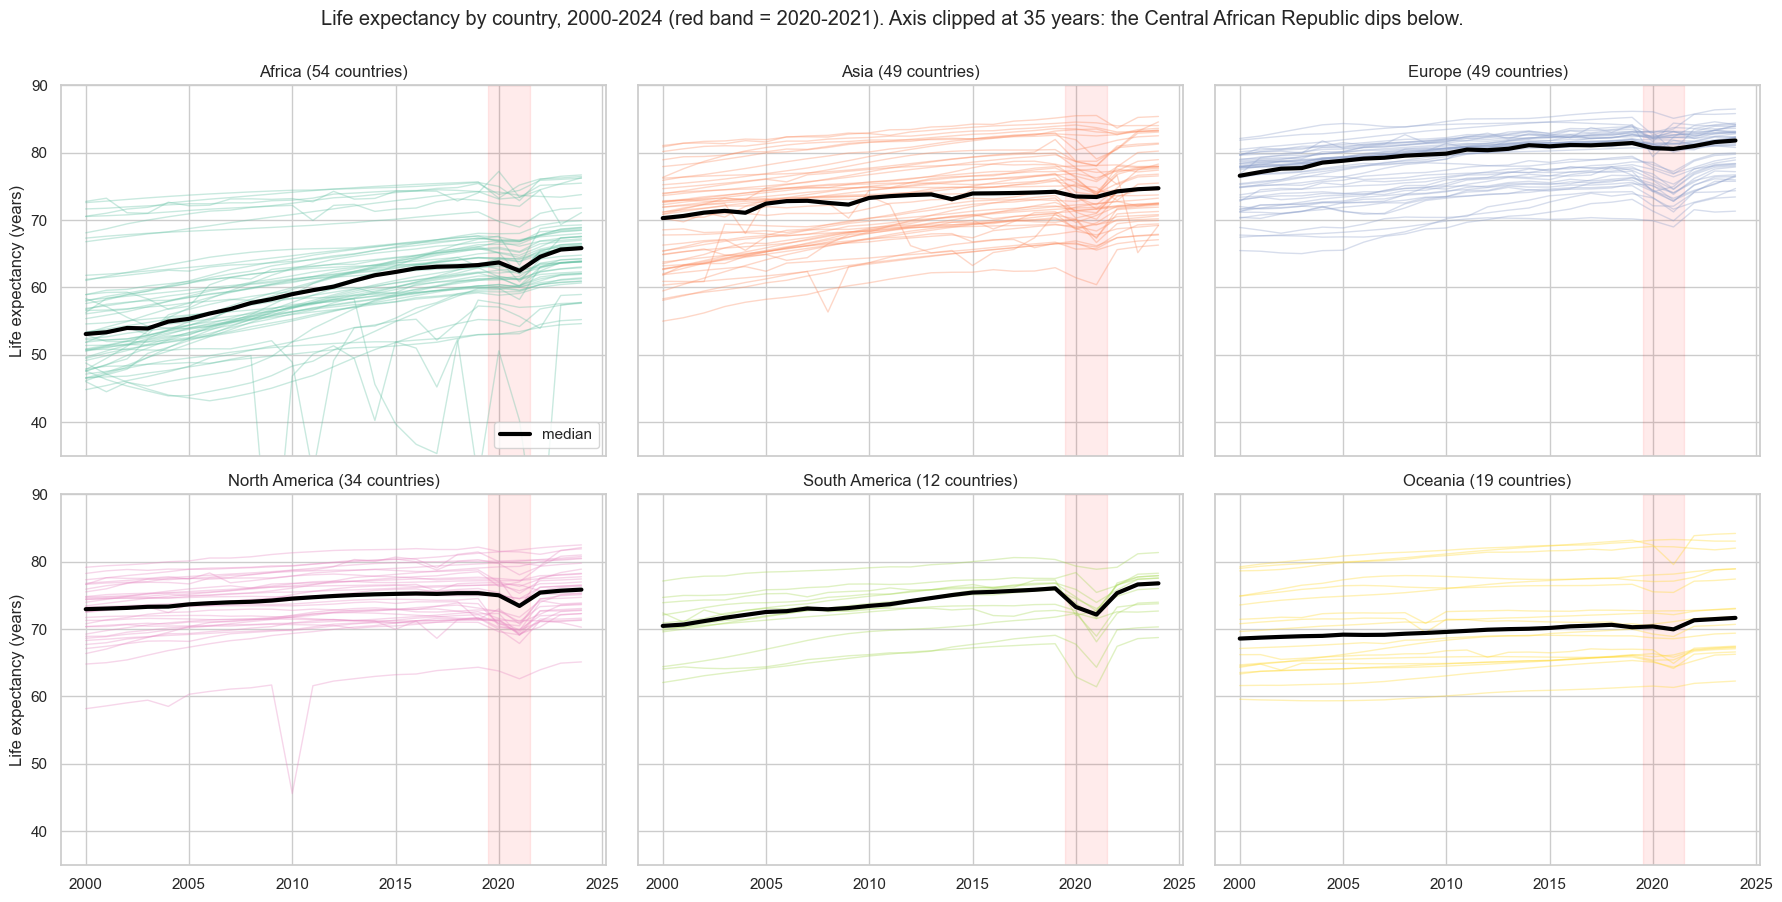

In [14]:
palette = dict(zip(cont_order, sns.color_palette('Set2', len(cont_order))))
piv_le = df.pivot(index='year', columns='Country Name', values='life_expectancy')
cont_of_country = df.drop_duplicates('Country Name').set_index('Country Name')['continent']

# Figure 3: every country's life-expectancy path, one panel per continent, with the continent median in bold.
fig, axes = plt.subplots(2, 3, figsize=(18, 9), sharex=True, sharey=True)
for ax, cont in zip(axes.ravel(), cont_order):
    names = cont_of_country[cont_of_country == cont].index
    for n in names:
        ax.plot(piv_le.index, piv_le[n], color=palette[cont], alpha=0.35, lw=1)
    ax.plot(piv_le.index, piv_le[names].median(axis=1), color='black', lw=3, label='median')
    ax.set(title=f'{cont} ({len(names)} countries)', ylim=(35, 90))
    ax.axvspan(2019.5, 2021.5, color='red', alpha=0.08)
for ax in axes[:, 0]:
    ax.set_ylabel('Life expectancy (years)')
axes[0, 0].legend(loc='lower right')
fig.suptitle('Life expectancy by country, 2000-2024 (red band = 2020-2021). Axis clipped at 35 years: the Central African Republic dips below.', y=1.0)
plt.tight_layout()
plt.show()

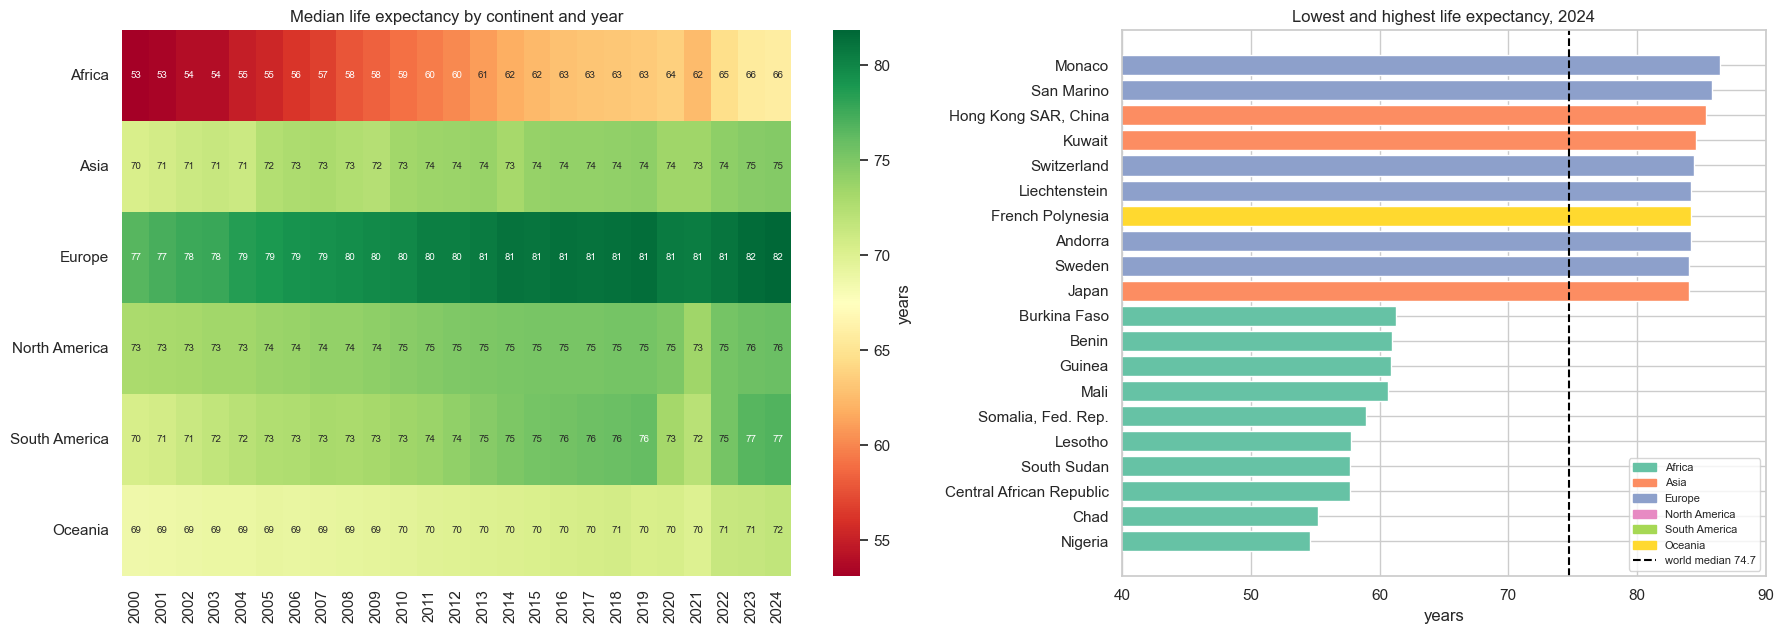

In [15]:
# Figure 4: (a) median life expectancy by continent and year; (b) the 10 lowest and 10 highest countries in 2024.
med = df.groupby(['continent', 'year'])['life_expectancy'].median().unstack().reindex(cont_order)
le24 = df[df['year'] == 2024].set_index('Country Name')['life_expectancy'].sort_values()
ext = pd.concat([le24.head(10), le24.tail(10)])

fig, axes = plt.subplots(1, 2, figsize=(18, 6.5), gridspec_kw={'width_ratios': [1.3, 1]})
sns.heatmap(med, cmap='RdYlGn', annot=True, fmt='.0f', annot_kws={'size': 7}, cbar_kws={'label': 'years'}, ax=axes[0])
axes[0].set(title='Median life expectancy by continent and year', xlabel='', ylabel='')
colors = [palette[cont_of_country[n]] for n in ext.index]
axes[1].barh(ext.index, ext.values, color=colors)
axes[1].axvline(le24.median(), color='black', ls='--', label=f'world median {le24.median():.1f}')
axes[1].set(title='Lowest and highest life expectancy, 2024', xlabel='years', xlim=(40, 90))
axes[1].legend(handles=[plt.Rectangle((0, 0), 1, 1, color=palette[c]) for c in cont_order] +
               [plt.Line2D([0], [0], color='black', ls='--')],
               labels=cont_order + [f'world median {le24.median():.1f}'], loc='lower right', fontsize=8)
plt.tight_layout()
plt.show()

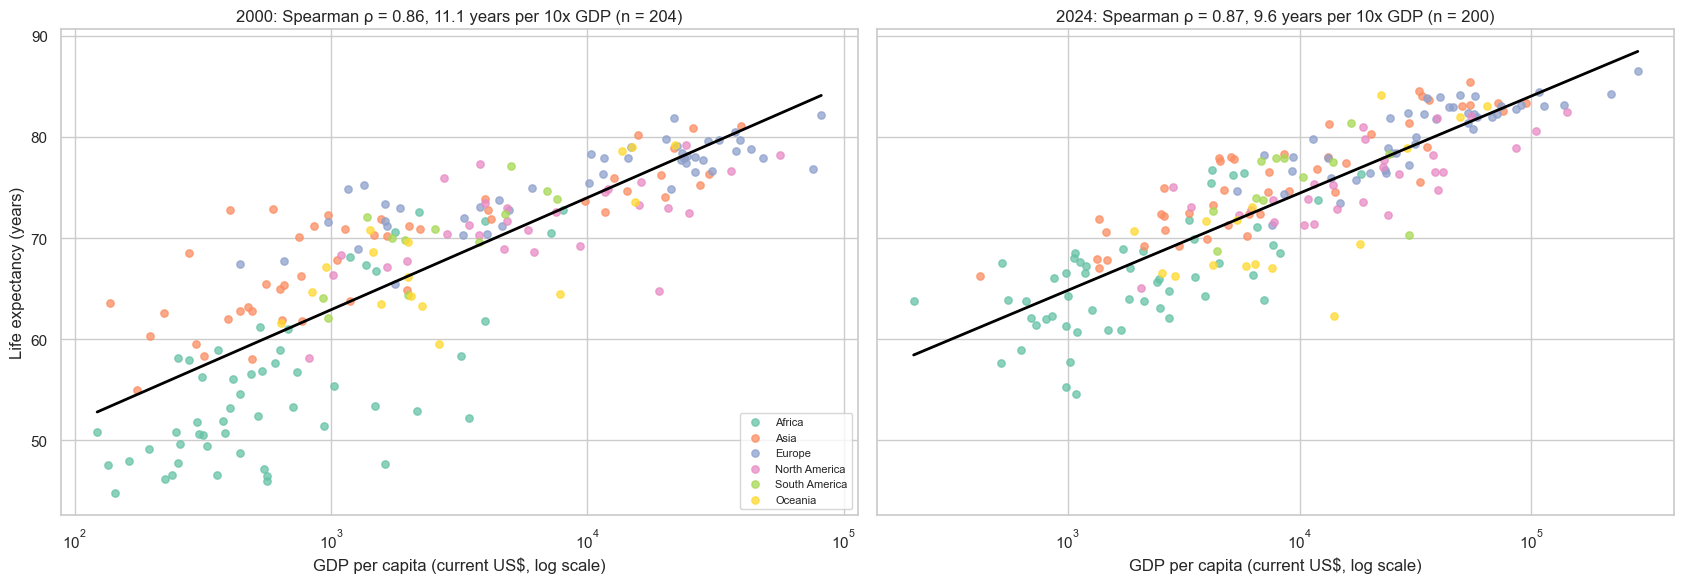

In [16]:
# Figure 5: life expectancy against GDP per capita (log scale) in 2000 and 2024.
fig, axes = plt.subplots(1, 2, figsize=(17, 6), sharey=True)
for ax, yr in zip(axes, [2000, 2024]):
    d = df[df['year'] == yr].dropna(subset=['gdp_per_capita', 'life_expectancy'])
    for cont in cont_order:
        s = d[d['continent'] == cont]
        ax.scatter(s['gdp_per_capita'], s['life_expectancy'], s=28, alpha=0.75, color=palette[cont], label=cont)
    b = np.polyfit(d['log_gdp'], d['life_expectancy'], 1)
    xs = np.linspace(d['log_gdp'].min(), d['log_gdp'].max(), 100)
    ax.plot(10 ** xs, b[0] * xs + b[1], color='black', lw=2)
    rho = stats.spearmanr(d['log_gdp'], d['life_expectancy'])[0]
    ax.set_xscale('log')
    ax.set(title=f'{yr}: Spearman ρ = {rho:.2f}, {b[0]:.1f} years per 10x GDP (n = {len(d)})',
           xlabel='GDP per capita (current US$, log scale)')
axes[0].set_ylabel('Life expectancy (years)')
axes[0].legend(fontsize=8, loc='lower right')
plt.tight_layout()
plt.show()

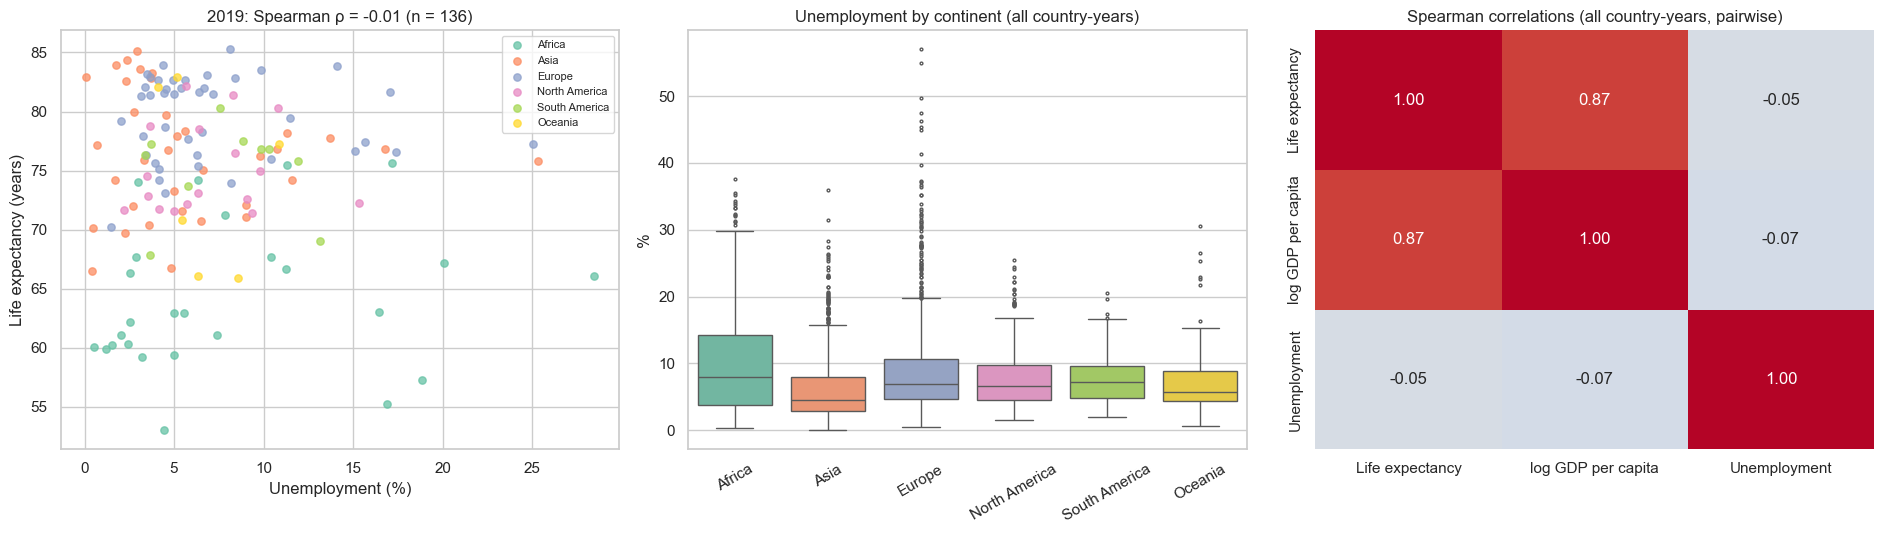

In [17]:
# Figure 6: life expectancy and unemployment, 2019 (last full pre-pandemic year) and continent differences.
d19 = df[df['year'] == 2019].dropna(subset=['unemployment_rate', 'life_expectancy'])
fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))
for cont in cont_order:
    s = d19[d19['continent'] == cont]
    axes[0].scatter(s['unemployment_rate'], s['life_expectancy'], s=28, alpha=0.75, color=palette[cont], label=cont)
rho = stats.spearmanr(d19['unemployment_rate'], d19['life_expectancy'])[0]
axes[0].set(title=f'2019: Spearman ρ = {rho:.2f} (n = {len(d19)})', xlabel='Unemployment (%)', ylabel='Life expectancy (years)')
axes[0].legend(fontsize=8)

sns.boxplot(data=df, x='continent', y='unemployment_rate', order=cont_order, hue='continent', palette=palette,
            legend=False, ax=axes[1], fliersize=2)
axes[1].set(title='Unemployment by continent (all country-years)', xlabel='', ylabel='%')
axes[1].tick_params(axis='x', rotation=30)

corr = df[['life_expectancy', 'log_gdp', 'unemployment_rate']].corr(method='spearman')
corr.index = corr.columns = ['Life expectancy', 'log GDP per capita', 'Unemployment']
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, ax=axes[2], cbar=False)
axes[2].set(title='Spearman correlations (all country-years, pairwise)')
plt.tight_layout()
plt.show()

### 5e. Trends, patterns and relationships

First the trend itself: how fast did the world move, when did it stall, and how did regions differ?

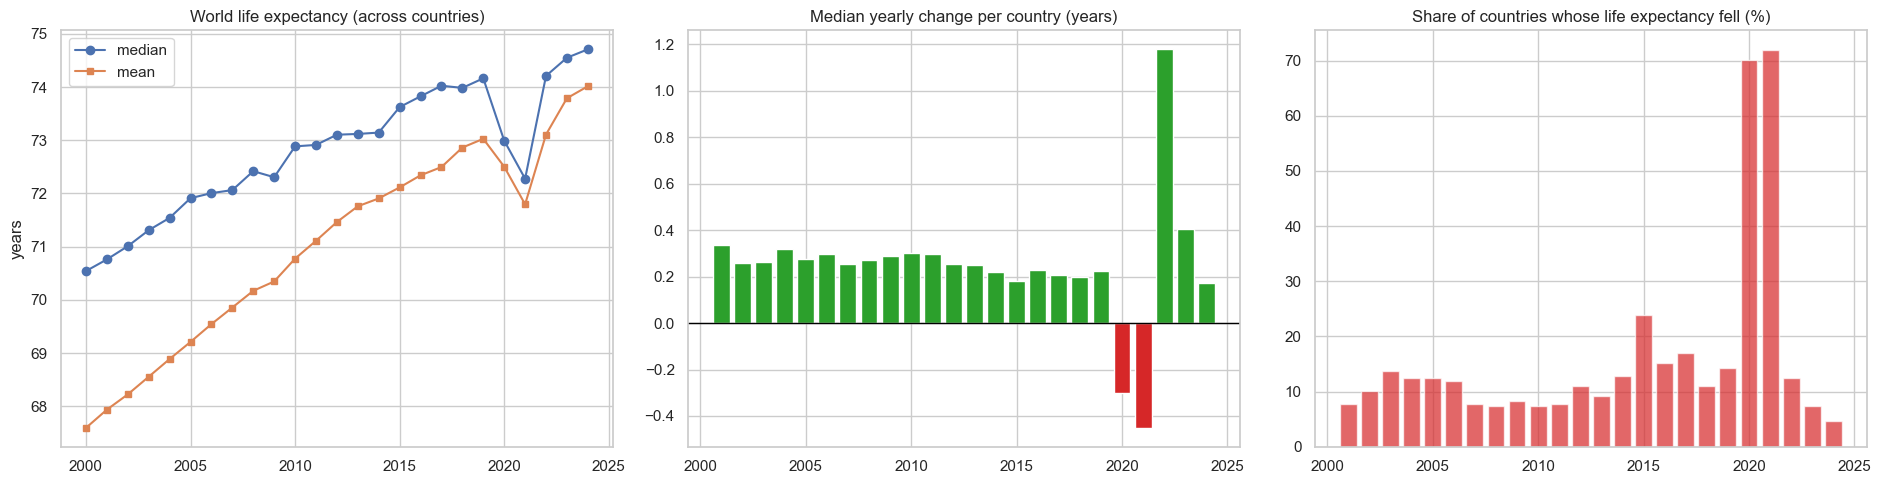

      median_le  mean_le  median_change  share_declined_%
year                                                     
2000      70.54    67.59            NaN               NaN
2010      72.89    70.78           0.30              7.37
2019      74.17    73.03           0.23             14.29
2020      72.99    72.50          -0.30             70.05
2021      72.28    71.80          -0.45             71.89
2022      74.21    73.11           1.18             12.44
2023      74.55    73.79           0.41              7.37
2024      74.71    74.02           0.17              4.61

Years with the most countries going backwards:
year
2021    72.0
2020    70.0
2015    24.0
2017    17.0
2016    15.0


In [18]:
# Figure 7: world median life expectancy, yearly change, and the share of countries that went backwards.
d_le = df.sort_values(['Country Name', 'year']).copy()
d_le['d_le'] = d_le.groupby('Country Name')['life_expectancy'].diff()
yr = pd.DataFrame({
    'median_le': df.groupby('year')['life_expectancy'].median(),
    'mean_le': df.groupby('year')['life_expectancy'].mean(),
    'median_change': d_le.groupby('year')['d_le'].median(),
    'share_declined_%': d_le.dropna(subset=['d_le']).groupby('year')['d_le'].apply(lambda s: 100 * (s < 0).mean())})
fig, axes = plt.subplots(1, 3, figsize=(19, 5))
axes[0].plot(yr.index, yr['median_le'], marker='o', label='median')
axes[0].plot(yr.index, yr['mean_le'], marker='s', ms=4, label='mean')
axes[0].set(title='World life expectancy (across countries)', ylabel='years'); axes[0].legend()
axes[1].bar(yr.index[1:], yr['median_change'][1:], color=np.where(yr['median_change'][1:] < 0, 'tab:red', 'tab:green'))
axes[1].axhline(0, color='black', lw=1)
axes[1].set(title='Median yearly change per country (years)')
axes[2].bar(yr.index[1:], yr['share_declined_%'][1:], color='tab:red', alpha=0.7)
axes[2].set(title='Share of countries whose life expectancy fell (%)')
plt.tight_layout()
plt.show()
print(yr.loc[[2000, 2010, 2019, 2020, 2021, 2022, 2023, 2024]].round(2).to_string())
print('\nYears with the most countries going backwards:')
print(yr['share_declined_%'].iloc[1:].sort_values(ascending=False).head(5).round(0).to_string())

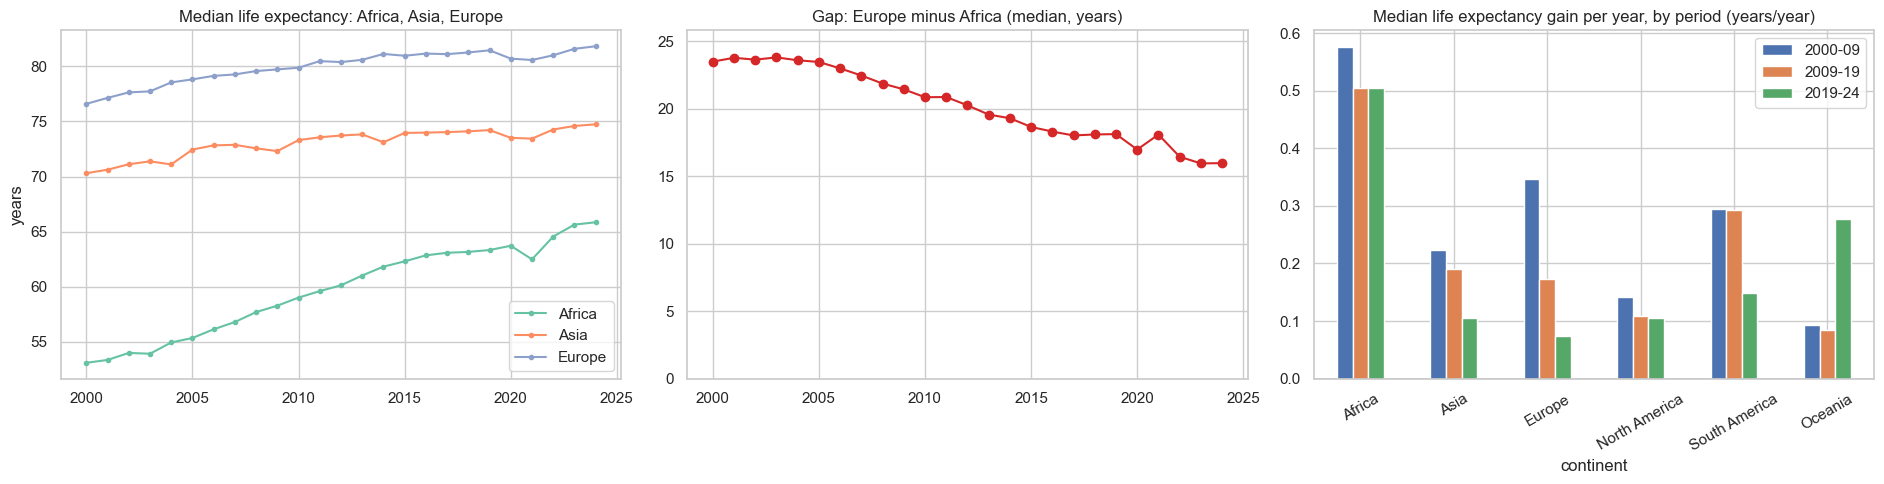

Europe-Africa gap: 23.5 years (2000), 18.1 (2019), 16.0 (2024)
               2000-09  2009-19  2019-24
continent                               
Africa            0.58     0.51     0.50
Asia              0.22     0.19     0.11
Europe            0.35     0.17     0.07
North America     0.14     0.11     0.10
South America     0.30     0.29     0.15
Oceania           0.09     0.08     0.28


In [19]:
# Figure 8: comparing regions. Africa vs Europe vs Asia (medians), the gap between them, and gains in each decade.
reg = df.groupby(['year', 'continent'])['life_expectancy'].median().unstack()
fig, axes = plt.subplots(1, 3, figsize=(19, 5))
for c in ['Africa', 'Asia', 'Europe']:
    axes[0].plot(reg.index, reg[c], marker='o', ms=3, color=palette[c], label=c)
axes[0].set(title='Median life expectancy: Africa, Asia, Europe', ylabel='years'); axes[0].legend()
gap = (reg['Europe'] - reg['Africa'])
axes[1].plot(gap.index, gap.values, marker='o', color='tab:red')
axes[1].set(title='Gap: Europe minus Africa (median, years)', ylim=(0, gap.max() + 2))

periods = {'2000-09': (2000, 2009), '2009-19': (2009, 2019), '2019-24': (2019, 2024)}
gains = pd.DataFrame({k: (reg.loc[b] - reg.loc[a]) / (b - a) for k, (a, b) in periods.items()}).reindex(cont_order)
gains.plot.bar(ax=axes[2], rot=30)
axes[2].axhline(0, color='black', lw=1)
axes[2].set(title='Median life expectancy gain per year, by period (years/year)')
plt.tight_layout()
plt.show()
print(f'Europe-Africa gap: {gap[2000]:.1f} years (2000), {gap[2019]:.1f} (2019), {gap[2024]:.1f} (2024)')
print(gains.round(2).to_string())

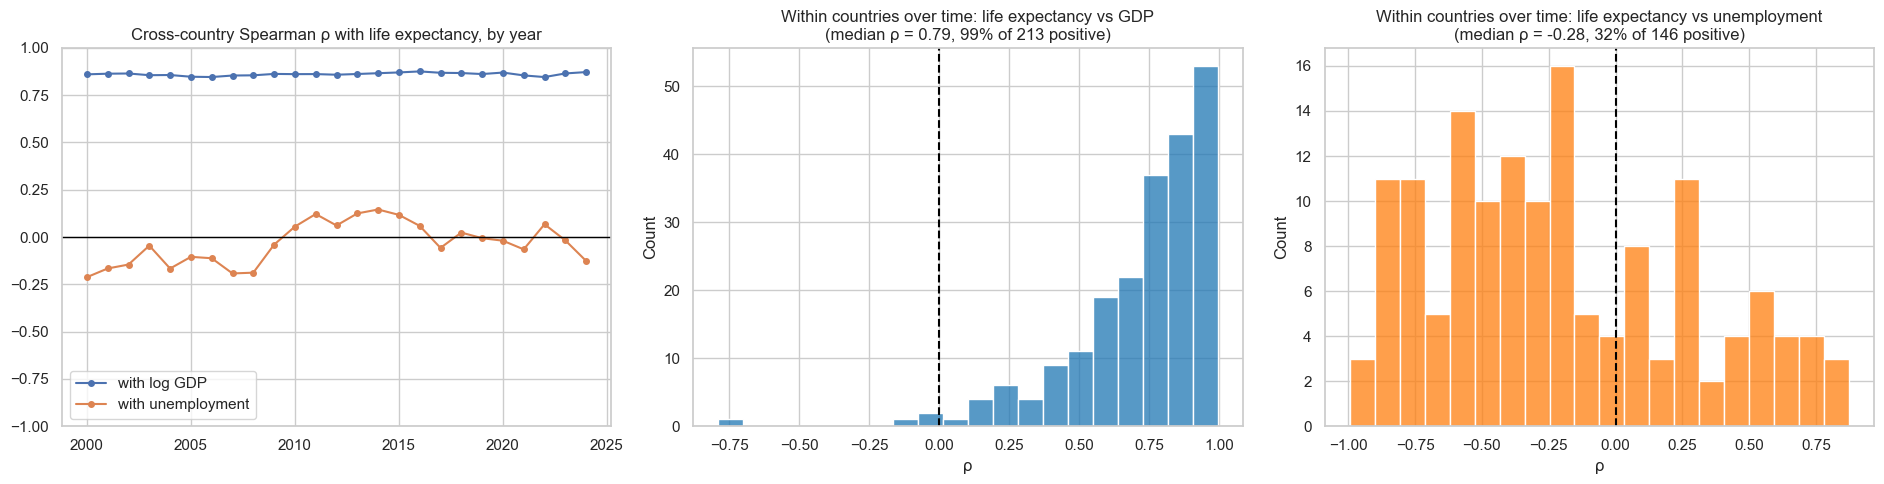

      with log GDP  with unemployment
year                                 
2000          0.86              -0.21
2010          0.86               0.06
2019          0.86              -0.01
2020          0.87              -0.02
2024          0.87              -0.13
Pooled across all country-years: LE vs log GDP rho = 0.87; LE vs unemployment rho = -0.05


In [20]:
# Figure 9: relationships with the supporting indicators over time.
# For each year, the Spearman correlation across countries of life expectancy with log GDP and with unemployment.
rel = pd.DataFrame({
    'with log GDP': df.groupby('year').apply(lambda g: g['life_expectancy'].corr(g['log_gdp'], method='spearman'), include_groups=False),
    'with unemployment': df.groupby('year').apply(lambda g: g['life_expectancy'].corr(g['unemployment_rate'], method='spearman'), include_groups=False)})
nn = df.groupby('year')['unemployment_rate'].count()

# Within-country: correlate each country's own life expectancy and GDP over time (levels)
def within(g, x):
    g = g.dropna(subset=[x, 'life_expectancy'])
    return g['life_expectancy'].corr(g[x], method='spearman') if len(g) >= 8 else np.nan
w_gdp = df.groupby('Country Name').apply(lambda g: within(g, 'log_gdp'), include_groups=False).dropna()
w_une = df.groupby('Country Name').apply(lambda g: within(g, 'unemployment_rate'), include_groups=False).dropna()

fig, axes = plt.subplots(1, 3, figsize=(19, 5))
rel.plot(ax=axes[0], marker='o', ms=4)
axes[0].axhline(0, color='black', lw=1); axes[0].set(title='Cross-country Spearman ρ with life expectancy, by year', ylim=(-1, 1), xlabel='')
sns.histplot(w_gdp, bins=20, ax=axes[1], color='tab:blue'); axes[1].axvline(0, color='black', ls='--')
axes[1].set(title=f'Within countries over time: life expectancy vs GDP\n(median ρ = {w_gdp.median():.2f}, {100 * (w_gdp > 0).mean():.0f}% of {len(w_gdp)} positive)', xlabel='ρ')
sns.histplot(w_une, bins=20, ax=axes[2], color='tab:orange'); axes[2].axvline(0, color='black', ls='--')
axes[2].set(title=f'Within countries over time: life expectancy vs unemployment\n(median ρ = {w_une.median():.2f}, {100 * (w_une > 0).mean():.0f}% of {len(w_une)} positive)', xlabel='ρ')
plt.tight_layout()
plt.show()
print(rel.loc[[2000, 2010, 2019, 2020, 2024]].round(2).to_string())
print(f'Pooled across all country-years: LE vs log GDP rho = {df["life_expectancy"].corr(df["log_gdp"], method="spearman"):.2f}; '
      f'LE vs unemployment rho = {df["life_expectancy"].corr(df["unemployment_rate"], method="spearman"):.2f}')

#### What the visualisations in 5c show

- **Figure 3 (life expectancy over time by continent).** Every continent's median rises across 2000-2024, but the levels are ordered and the order never changes: Europe and Oceania's richer members sit highest, Africa lowest. The spread *within* Africa and Asia is much wider than within Europe, so a continent median hides large differences between countries.
- **Figure 4 (continent x year heatmap and extremes).** The heatmap shows Africa making the largest absolute gains, while Europe's colour barely shifts after about 2010. The 2024 lowest-ranked countries are overwhelmingly African; the highest-ranked are in Europe and East Asia.
- **Figure 5 (life expectancy vs GDP per capita).** Plotted on a log axis the relationship is strongly positive and concave: moving from very poor to moderately rich countries is associated with large gains, while beyond roughly US$10,000-20,000 per head the curve flattens. The log-linear slope is about 11.1 years per tenfold GDP increase in 2000 and about 9.6 in 2024, with a Spearman rho of roughly 0.86-0.87. This is an association between countries, not evidence that income causes longer lives.
- **Figure 6 (life expectancy vs unemployment).** Here there is no clear pattern: the scatter is a cloud, and the Spearman coefficient is close to zero. Unemployment rates also differ by continent, but the rate itself does not line up with life expectancy.

#### What the trends and relationships in 5e show

- **Figure 7 (world level).** The median country gains life expectancy in most years, with an abrupt dip in 2020-2021 when 70-72% of countries fell year-on-year (the COVID-19 period), followed by a rebound in 2022.
- **Figure 8 (regions).** Africa gained steadily, about 0.5-0.58 years per calendar year, whereas Europe's gain slowed from about 0.35 to 0.07 years per year. As a result the Europe-Africa gap in median life expectancy narrowed from about 23.5 years to about 16 years (convergence, though a large gap remains). Oceania's gain accelerated (0.09 to 0.28 years per year).
- **Figure 9 (strength of the relationships).** The cross-country LE-GDP correlation is high and very stable in every year. Within countries over time, 98.6% of the 214 countries have a positive LE-logGDP correlation (median rho 0.79), but this partly reflects both series trending upward together. For unemployment the within-country picture is mixed: median rho is -0.28 and only 31% of the 147 countries with enough data are positive, so any link is weak and inconsistent. Unemployment coverage is also much lower than for the other indicators.

## 4. The eight questions

Questions 3, 4, 5 and 7 use life expectancy together with a supporting indicator (GDP per capita or unemployment). All relationships reported are associations, not causal effects.

### Question 1: Which countries gained and lost the most life expectancy between 2000 and 2024?

Countries with both years: 217; median change: 5.4 years

Largest gains:
Country Name
Zimbabwe        17.0
Botswana        17.0
Sierra Leone    17.1
Angola          18.3
Uganda          18.8
Zambia          20.0
Rwanda          20.2
Malawi          21.4

Smallest gains / losses:
Country Name
West Bank and Gaza               -1.1
Dominica                         -0.4
Venezuela, RB                     0.3
Jamaica                           0.3
Libya                             0.6
St. Vincent and the Grenadines    1.0
Samoa                             1.0
Fiji                              1.3


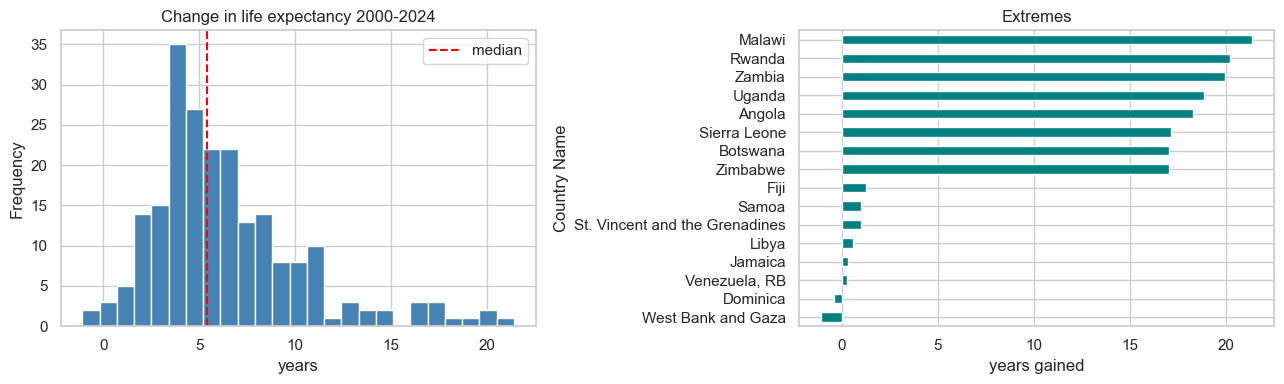

In [21]:
a = piv_le = df.pivot(index='Country Name', columns='year', values='life_expectancy')
chg = (a[2024] - a[2000]).dropna().sort_values()
print(f'Countries with both years: {len(chg)}; median change: {chg.median():.1f} years')
print('\nLargest gains:'); print(chg.tail(8).round(1).to_string())
print('\nSmallest gains / losses:'); print(chg.head(8).round(1).to_string())
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
chg.plot.hist(bins=25, ax=ax[0], color='steelblue', edgecolor='white')
ax[0].axvline(chg.median(), color='red', ls='--', label='median'); ax[0].set(title='Change in life expectancy 2000-2024', xlabel='years'); ax[0].legend()
pd.concat([chg.tail(8), chg.head(8)]).sort_values().plot.barh(ax=ax[1], color='teal'); ax[1].set(title='Extremes', xlabel='years gained')
plt.tight_layout(); plt.show()

**Answer.** Almost every country gained; the median gain is about 5.4 years. The largest gains are concentrated in countries that started from low levels (many in Africa and parts of Asia), while the smallest gains or losses are a handful of countries, some of which may reflect conflict, epidemics or unreliable estimates (e.g. the anomalies already noted for the Central African Republic). Catching up from a low base is easier than adding years at a high level.

### Question 2: Are countries converging in life expectancy (is the spread narrowing)?

       std    IQR  P90-P10
year                      
2000  9.64  13.02    26.62
2005  9.26  12.03    25.67
2010  8.78  12.59    23.81
2015  8.22  12.25    21.81
2019  7.97  11.48    20.50
2021  7.71  10.78    20.94
2024  7.11  11.04    19.15


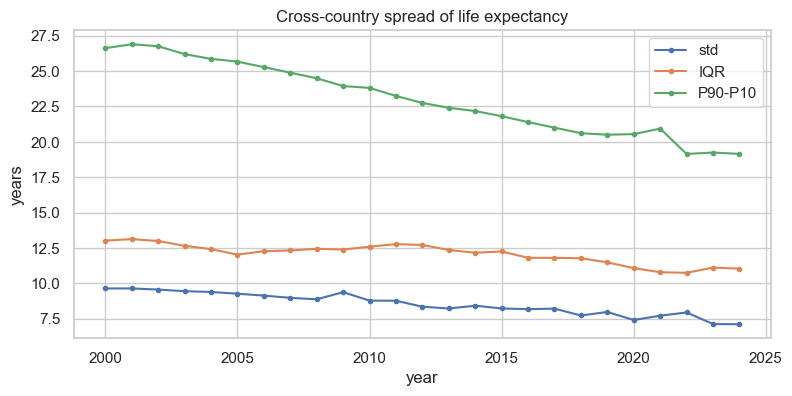

Spearman(start level, gain): SignificanceResult(statistic=np.float64(-0.6412627017378003), pvalue=np.float64(1.5684934233151944e-26))


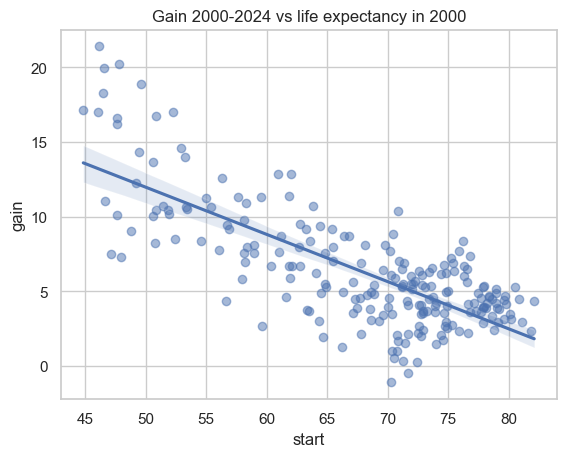

In [22]:
sd = a.std(); iqr = a.quantile(.75) - a.quantile(.25); rng = a.quantile(.9) - a.quantile(.1)
conv = pd.DataFrame({'std': sd, 'IQR': iqr, 'P90-P10': rng})
print(conv.loc[[2000, 2005, 2010, 2015, 2019, 2021, 2024]].round(2))
conv.plot(figsize=(9, 4), marker='o', ms=3, title='Cross-country spread of life expectancy'); plt.ylabel('years'); plt.show()
# regression of gain on starting level
s = pd.DataFrame({'start': a[2000], 'gain': a[2024] - a[2000]}).dropna()
print('Spearman(start level, gain):', stats.spearmanr(s.start, s.gain))
sns.regplot(data=s, x='start', y='gain', scatter_kws={'alpha': .5}); plt.title('Gain 2000-2024 vs life expectancy in 2000'); plt.show()

**Answer.** Yes, the spread (standard deviation, IQR and P90-P10) narrows over the period, and countries that started lower gained more (negative rank correlation between starting level and gain). This is convergence in the sense of shrinking cross-country dispersion; it does not mean the gap has disappeared.

### Question 3 (life expectancy + GDP per capita): How strongly is life expectancy associated with income, and where do returns flatten?

              n  gdp_median  le_median  le_min  le_max
income_band                                           
Q1 lowest    40      1088.7       64.7    54.6    71.9
Q2           40      3972.6       71.8    62.1    78.0
Q3           40      7852.4       73.9    63.9    81.3
Q4           40     23442.2       77.7    62.3    84.6
Q5 highest   40     56342.8       82.7    74.7    86.5
Spearman: SignificanceResult(statistic=np.float64(0.8721953048826222), pvalue=np.float64(2.102146995802395e-63))


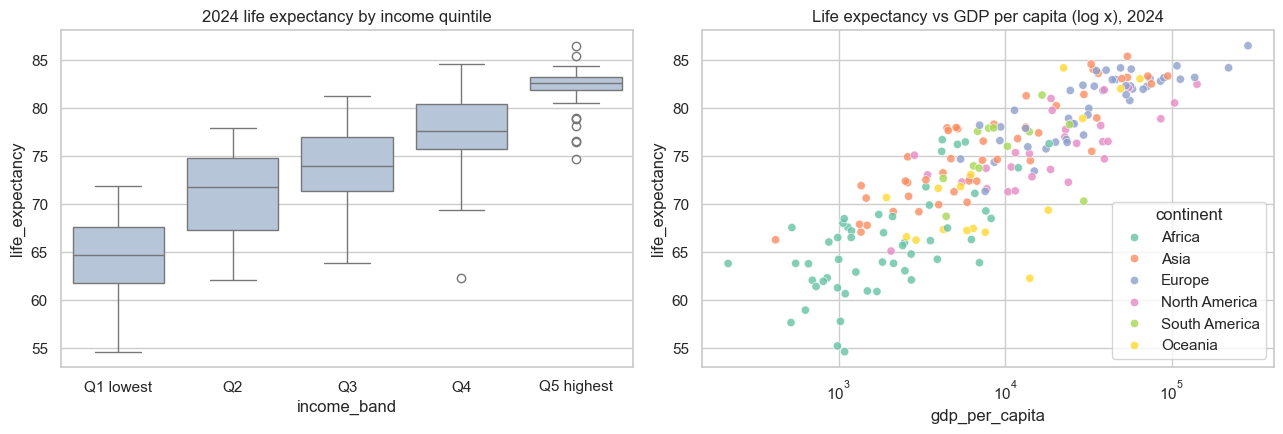

In [23]:
x = df[df.year == 2024].dropna(subset=['life_expectancy', 'log_gdp']).copy()
x['income_band'] = pd.qcut(x.gdp_per_capita, 5, labels=['Q1 lowest', 'Q2', 'Q3', 'Q4', 'Q5 highest'])
t = x.groupby('income_band', observed=True).agg(n=('life_expectancy', 'size'), gdp_median=('gdp_per_capita', 'median'),
        le_median=('life_expectancy', 'median'), le_min=('life_expectancy', 'min'), le_max=('life_expectancy', 'max')).round(1)
print(t)
print('Spearman:', stats.spearmanr(x.log_gdp, x.life_expectancy))
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
sns.boxplot(data=x, x='income_band', y='life_expectancy', ax=ax[0], color='lightsteelblue'); ax[0].set(title='2024 life expectancy by income quintile')
sns.scatterplot(data=x, x='gdp_per_capita', y='life_expectancy', hue='continent', hue_order=cont_order, palette=palette, ax=ax[1], alpha=.8)
ax[1].set_xscale('log'); ax[1].set(title='Life expectancy vs GDP per capita (log x), 2024'); plt.tight_layout(); plt.show()

**Answer.** There is a strong positive monotonic association (Spearman about 0.87). The median rises sharply from the poorest to the middle quintiles and much more slowly at the top, i.e. diminishing returns. Within a quintile, the range of life expectancy is wide, so income alone does not determine it. This is an association between countries; it does not show that raising income causes longer lives.

### Question 4 (life expectancy + GDP per capita): Do countries whose income grew faster also gain more life expectancy?

201 countries (2001-2023, avoids missing end years)
Spearman(growth in logGDP, LE gain): SignificanceResult(statistic=np.float64(0.2671960496512853), pvalue=np.float64(0.00012582869325920062))
Spearman(growth in logGDP, starting LE): SignificanceResult(statistic=np.float64(-0.24084536753561844), pvalue=np.float64(0.000572931351476768))
               dlogGDP   dLE
continent                   
Africa            0.45  9.10
Asia              0.62  5.73
Europe            0.49  4.23
North America     0.35  3.25
Oceania           0.48  3.15
South America     0.57  5.31


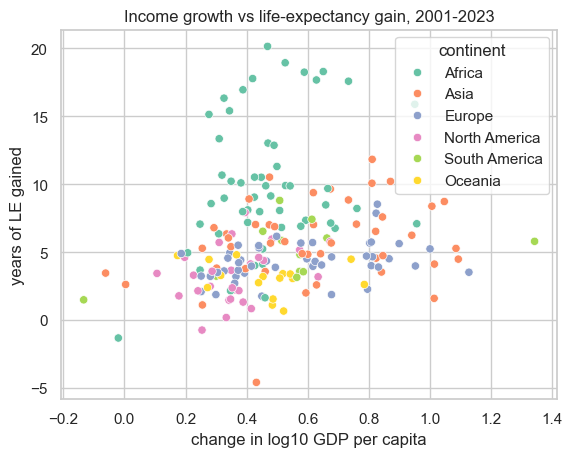

In [24]:
f = df.pivot(index='Country Name', columns='year', values='log_gdp')
g = pd.DataFrame({'dlogGDP': f[2023] - f[2001], 'dLE': a[2023] - a[2001], 'start_le': a[2001], 'continent': pd.Series(cont_of_country)}).dropna()
print(len(g), 'countries (2001-2023, avoids missing end years)')
r = stats.spearmanr(g.dlogGDP, g.dLE); print('Spearman(growth in logGDP, LE gain):', r)
r2 = stats.spearmanr(g.dlogGDP, g.start_le); print('Spearman(growth in logGDP, starting LE):', r2)
print(g.groupby('continent')[['dlogGDP', 'dLE']].median().round(2))
sns.scatterplot(data=g, x='dlogGDP', y='dLE', hue='continent', hue_order=cont_order, palette=palette)
plt.title('Income growth vs life-expectancy gain, 2001-2023'); plt.xlabel('change in log10 GDP per capita'); plt.ylabel('years of LE gained'); plt.show()

**Answer.** Income growth and life-expectancy gain are only weakly positively associated (Spearman about 0.27, versus about 0.87 for levels in Question 3). Countries that were already long-lived had little room to gain regardless of growth, while many low-income countries gained a lot. Growth in nominal US$ GDP also reflects exchange-rate and price changes, so this is a noisy measure. Levels and changes tell different stories here.

### Question 5 (life expectancy + unemployment): Is a higher unemployment rate associated with lower life expectancy?

161 countries with >=5 unemployment observations in 2000-2019
All: SignificanceResult(statistic=np.float64(0.04987635150678629), pvalue=np.float64(0.5297943110421502))
Africa         n= 30 rho=+0.29
Asia           n= 44 rho=-0.06
Europe         n= 45 rho=-0.32
North America  n= 25 rho=+0.10
South America  n= 11 rho=+0.49


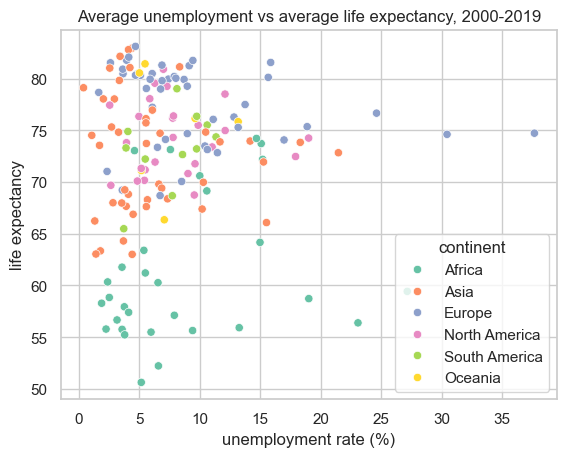

In [25]:
u = df[df.year.between(2000, 2019)].groupby('Country Name').agg(unemp=('unemployment_rate', 'mean'), lexp=('life_expectancy', 'mean'), n=('unemployment_rate', 'count'), continent=('continent', 'first'))
u = u[u.n >= 5].dropna()
print(len(u), 'countries with >=5 unemployment observations in 2000-2019')
print('All:', stats.spearmanr(u.unemp, u.lexp))
for c in cont_order:
    s_ = u[u.continent == c]
    if len(s_) >= 8: print(f'{c:14s} n={len(s_):3d} rho={stats.spearmanr(s_.unemp, s_.lexp)[0]:+.2f}')
sns.scatterplot(data=u, x='unemp', y='lexp', hue='continent', hue_order=cont_order, palette=palette)
plt.title('Average unemployment vs average life expectancy, 2000-2019'); plt.xlabel('unemployment rate (%)'); plt.ylabel('life expectancy'); plt.show()

**Answer.** No clear relationship. The rank correlation across countries is close to zero, and the sign differs by continent. Unemployment is measured in very different ways across economies (informal work, underemployment) and covers only about 59% of country-years, so the absence of a pattern may reflect measurement and coverage rather than a true lack of connection. Nothing here suggests a causal effect either way.

### Question 6: How do two contrasting countries compare, Rwanda and South Africa?

both found


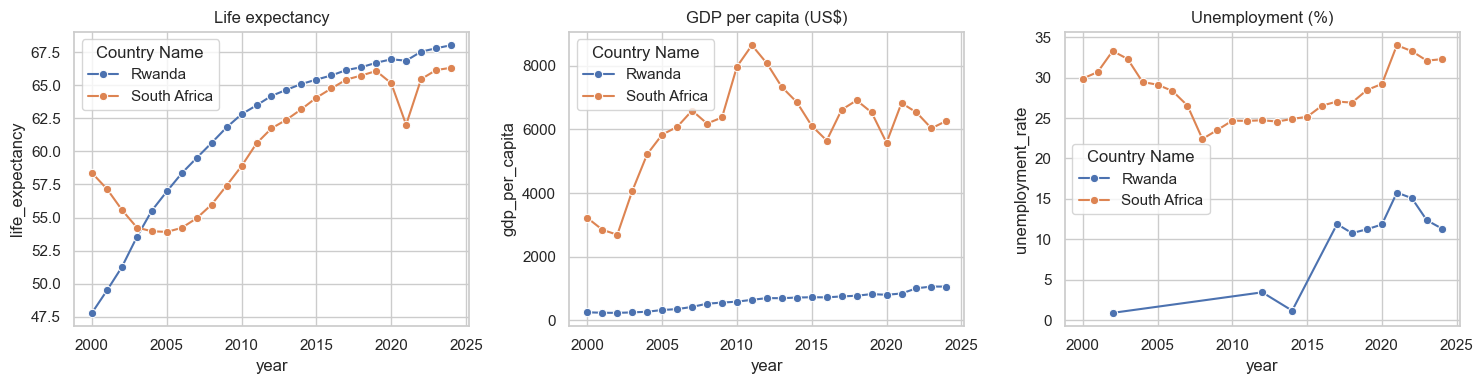

year          2000  2005  2010  2015  2019  2021  2024
Country Name                                          
Rwanda        47.8  57.0  62.8  65.4  66.7  66.8  68.0
South Africa  58.4  53.9  58.9  64.1  66.1  62.0  66.3


In [26]:
pair = ['Rwanda', 'South Africa']
print([p for p in pair if p not in a.index] or 'both found')
p = df[df['Country Name'].isin(pair)]
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for ind, t_, k in [('life_expectancy', 'Life expectancy', 0), ('gdp_per_capita', 'GDP per capita (US$)', 1), ('unemployment_rate', 'Unemployment (%)', 2)]:
    sns.lineplot(data=p, x='year', y=ind, hue='Country Name', ax=ax[k], marker='o'); ax[k].set_title(t_)
plt.tight_layout(); plt.show()
print(a.loc[pair, [2000, 2005, 2010, 2015, 2019, 2021, 2024]].round(1))

**Answer.** The two countries moved in different ways: Rwanda started far lower and climbed rapidly, while South Africa fell from 58.4 (2000) to 53.9 (2005) before recovering, and shows a sharp COVID-era drop (66.1 in 2019 to 62.0 in 2021). Their income and unemployment series look very different, so similar life expectancy trends do not map one-to-one onto the other indicators. Only two countries are compared, so this illustrates diversity rather than a general rule.

### Question 7 (life expectancy + GDP per capita): Which countries live much longer or shorter than their income predicts?

Fit: LE = 36.0 + 9.6 * log10(GDP); R^2 = 0.74
      Country Name     continent  gdp_per_capita  life_expectancy  resid
           Lebanon          Asia          4473.3             77.9    6.9
         Sri Lanka          Asia          4545.4             77.7    6.5
  French Polynesia       Oceania         22439.9             84.2    6.4
            Jordan          Asia          5073.9             78.0    6.4
Iran, Islamic Rep.          Asia          5190.2             77.9    6.1
        Bangladesh          Asia          2593.4             74.9    6.1
           Tunisia        Africa          4187.6             76.7    5.9
         Nicaragua North America          2847.9             75.1    5.9
            Naoero       Oceania         14048.2             62.3  -13.6
           Nigeria        Africa          1084.2             54.6  -10.5
              Chad        Africa           980.7             55.2   -9.5
 Equatorial Guinea        Africa          7003.6             63.9   -9.0
     

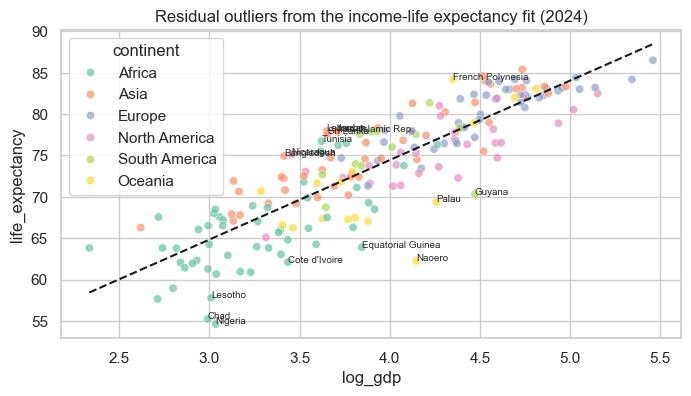

In [27]:
x = df[df.year == 2024].dropna(subset=['life_expectancy', 'log_gdp']).copy()
slope, icpt = np.polyfit(x.log_gdp, x.life_expectancy, 1)
x['pred'] = icpt + slope * x.log_gdp; x['resid'] = x.life_expectancy - x.pred
print(f'Fit: LE = {icpt:.1f} + {slope:.1f} * log10(GDP); R^2 = {np.corrcoef(x.log_gdp, x.life_expectancy)[0,1]**2:.2f}')
top = pd.concat([x.nlargest(8, 'resid'), x.nsmallest(8, 'resid')])[['Country Name', 'continent', 'gdp_per_capita', 'life_expectancy', 'resid']]
print(top.round(1).to_string(index=False))
plt.figure(figsize=(8, 4)); sns.scatterplot(data=x, x='log_gdp', y='life_expectancy', hue='continent', hue_order=cont_order, palette=palette, alpha=.7)
xs = np.linspace(x.log_gdp.min(), x.log_gdp.max(), 50); plt.plot(xs, icpt + slope * xs, 'k--')
for _, rw in top.iterrows(): plt.annotate(rw['Country Name'], (np.log10(rw.gdp_per_capita), rw.life_expectancy), fontsize=7)
plt.title('Residual outliers from the income-life expectancy fit (2024)'); plt.show()

**Answer.** Income explains a large share of the variation (R-squared shown above), but some countries are many years above or below the line. The largest positive residuals (about +6 to +7 years) are moderate-income countries such as Lebanon, Sri Lanka, Jordan, Iran and Bangladesh; the largest negative ones include Nauru (about -14 years, a very small state whose estimates may be unreliable), Nigeria and Chad (about -10 years). These are descriptive; the data here cannot explain why they differ.

### Question 8: Which countries suffered setbacks (declines), and how large was the COVID-19 dip and recovery?

Countries with most years of decline > 1 year:
Country Name
Central African Republic    7
Somalia, Fed. Rep.          5
Seychelles                  4
South Sudan                 4
South Africa                4
Syrian Arab Republic        4
Dominica                    3
Indonesia                   3
Libya                       3
Liechtenstein               3

Countries lower in 2021 than 2019: 84%; still below 2019 level in 2024: 9%
               drop_2019_2021  recovery_2021_2024  net_2019_2024
continent                                                       
Africa                  -0.48                1.95           1.62
Asia                    -0.91                1.70           0.81
Europe                  -1.04                1.61           0.40
North America           -1.60                2.31           0.65
Oceania                 -0.28                1.44           0.87
South America           -3.50                4.82           0.85


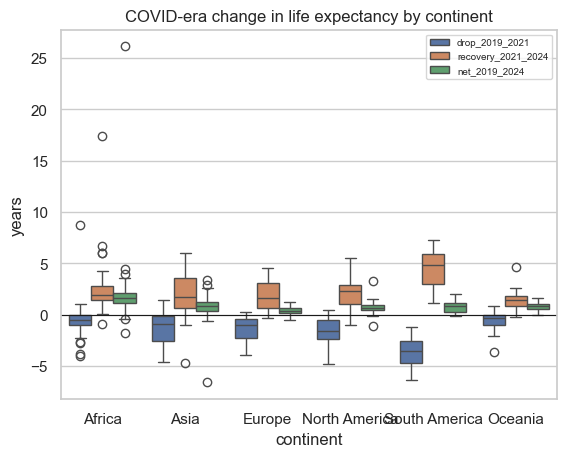

In [28]:
d = a.diff(axis=1)
big = (d < -1).sum(axis=1).sort_values(ascending=False)
print('Countries with most years of decline > 1 year:'); print(big.head(10).to_string())
c = pd.DataFrame({'drop_2019_2021': a[2021] - a[2019], 'recovery_2021_2024': a[2024] - a[2021], 'net_2019_2024': a[2024] - a[2019]}).dropna()
c['continent'] = pd.Series(cont_of_country)
print(f"\nCountries lower in 2021 than 2019: {(c.drop_2019_2021 < 0).mean():.0%}; still below 2019 level in 2024: {(c.net_2019_2024 < 0).mean():.0%}")
print(c.groupby('continent')[['drop_2019_2021', 'recovery_2021_2024', 'net_2019_2024']].median().round(2))
sns.boxplot(data=c.melt(id_vars='continent'), x='continent', y='value', hue='variable', order=cont_order); plt.axhline(0, color='k', lw=.8)
plt.title('COVID-era change in life expectancy by continent'); plt.ylabel('years'); plt.legend(fontsize=7); plt.show()

**Answer.** 84% of countries had lower life expectancy in 2021 than in 2019, and all but about 9% were back above their 2019 level by 2024. The dip was largest in North America (median about -1.6 years) and smallest in Oceania and Africa (about -0.3 to -0.5). Besides the pandemic, repeated sharp declines appear in a few countries with conflict or data anomalies (the Central African Republic stands out), which should be read with caution.

## 5. Summary and limitations

- Life expectancy rose almost everywhere in 2000-2024, with the largest gains in low-starting countries, so the cross-country spread narrowed. The COVID-19 years produced an abrupt dip in most countries and a rebound after 2021.
- Life expectancy is strongly associated with income across countries (about 0.87 rank correlation) with diminishing returns at high income; the association for income *growth* and life-expectancy *gain* is much weaker. For unemployment no clear relationship was found.
- All findings are associations; none show causation.
- Limitations: GDP is in current US$ (affected by prices and exchange rates); unemployment covers only about 59% of country-years; some countries (e.g. Central African Republic) have implausible swings; the continent mapping is hand-made; no missing values were imputed.